---
tags: [algorithm, optimization, variational]
---

---
tags: [algorithm, optimization, variational]
---

# QAOAでMaxCutを解く: 回路をゼロから構築する

このチュートリアルでは、Qamomileの低レベル回路プリミティブを使って、QAOA (Quantum Approximate Optimization Algorithm) のパイプラインをステップごとに構築します。高レベルな`QAOAConverter`は使わずに、以下の手順で進めます:

1. 小さなグラフでMaxCut問題を定義する。
2. スピン変数上のIsingモデルとして直接定式化する。
3. `@qkernel`を使ってQAOA回路をステップごとに記述する。
4. 古典オプティマイザで変分パラメータを最適化する。
5. 結果をデコードして可視化する。

最後に、`qamomile.stdlib.qaoa_state`が同じ回路を1つの関数呼び出しで提供することを示します。

## インストール

```bash
pip install qamomile
```

In [1]:
# 最新のQamomileをpipからインストールします！
# !pip install qamomile

In [2]:
from __future__ import annotations

import itertools
import math
import os

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from scipy.optimize import minimize

import qamomile as qm
from qamomile.optimization import BinaryModel, VarType
from qamomile.stdlib import ising_cost, qaoa_state, uniform_superposition, x_mixer

## MaxCut問題とは？

無向グラフ$G = (V, E)$が与えられたとき、**MaxCut**問題は頂点を2つの集合に分割し、2つの集合間を横切る辺の数を最大化する問題です。

MaxCutは本来、**スピン**変数で記述するのが自然な問題です。各頂点$i$にスピン$s_i \in \{+1, -1\}$を割り当て、頂点がどちら側に属するかを表現します。辺$(i, j)$が「カットされる」のは$s_i \ne s_j$のときなので、カットされる辺数は

$$
\text{MaxCut}(\boldsymbol{s})
= \sum_{(i,j) \in E} \frac{1 - s_i s_j}{2}
$$

と書けます。

MaxCutやスピングラス基底状態探索、Isingモデルベンチマークといったスピン変数で自然に定義される問題は、スピン領域で記述するのが最もクリーンです。そこで本チュートリアルではQUBO/バイナリ変数への寄り道は挟まず、最初から最後までスピン変数で扱います。

## グラフの作成

5頂点、6辺の小さなグラフを使います。全探索が可能な規模でありながら、自明でない構造を持っています。

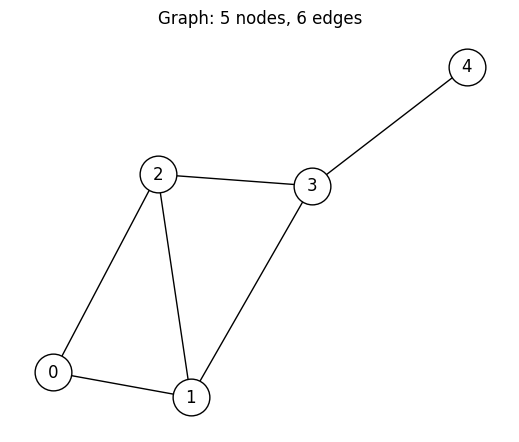

In [3]:
EDGES = ((0, 1), (0, 2), (1, 2), (1, 3), (2, 3), (3, 4))
graph = nx.Graph()
graph.add_edges_from(EDGES)
num_nodes = graph.number_of_nodes()

assert num_nodes == 5
assert graph.number_of_edges() == 6

positions = nx.spring_layout(graph, seed=42)
plt.figure(figsize=(5, 4))
nx.draw(
    graph,
    positions,
    with_labels=True,
    node_color="white",
    node_size=700,
    edgecolors="black",
)
plt.title(f"Graph: {num_nodes} nodes, {graph.number_of_edges()} edges")
plt.show()

## Ising定式化

cut countの最大化は、定数差を除けば、次のantiferromagnetic Ising Hamiltonianの
最小化と等価です。

$$
H_C(\mathbf{s})=\sum_{(i,j)\in E}s_i s_j.
$$

一般的なIsing形式$H=\sum_i h_i s_i+\sum_{i<j}J_{ij}s_i s_j$と比べると、
unweighted MaxCutにはlinear termがなく、各辺に一様なcouplingがあります。
`BinaryModel.from_ising`はこれらの係数を直接受け取るため、QUBOを経由する必要は
ありません。

In [4]:
model = BinaryModel.from_ising(
    {edge: 1.0 for edge in EDGES},
    variables=range(num_nodes),
)

assert model.vartype is VarType.SPIN
assert model.num_variables == 5
assert model.order == 2
assert BinaryModel.from_bytes(model.to_bytes()) == model

`BinaryModel`には、assignment問題やpenalty付き制約問題など、binary domainで自然に
表される問題のための`from_qubo()`と`from_hubo()`もあります。

## 厳密解（全探索）

QAOAを実行する前に、すべての$2^n = 32$通りのスピン配置を試して最適な分割を求めておきます。QAOAの結果と比較するための基準になります。

In [5]:
best_cut = 0
optimal_partitions = []
for spins in itertools.product((1, -1), repeat=num_nodes):
    cut = sum(spins[left] != spins[right] for left, right in EDGES)
    if cut > best_cut:
        best_cut = cut
        optimal_partitions = [spins]
    elif cut == best_cut:
        optimal_partitions.append(spins)

print(f"Optimal MaxCut value: {best_cut}")
print(f"Number of optimal partitions: {len(optimal_partitions)}")

assert best_cut == 5
assert len(optimal_partitions) == 2
assert all(
    tuple(-spin for spin in item) in optimal_partitions for item in optimal_partitions
)

Optimal MaxCut value: 5
Number of optimal partitions: 2


`model.hamiltonian`は、同じ目的関数をimmutableかつbackend-neutralな可換Pauli-Z wordの和で表したものです。Rustがcanonicalな多項式から導出するため、sourceページに別の係数変換を実装する必要はありません。

In [6]:
cost_hamiltonian = model.hamiltonian

assert cost_hamiltonian.num_qubits == 5
assert cost_hamiltonian.is_pairwise_commuting
assert min(model.energy(item) for item in optimal_partitions) == -4.0

## QAOA回路: 基本的な考え方

QAOAのアンザッツはパラメータ付き量子状態を準備します:

$$
|\boldsymbol{\gamma}, \boldsymbol{\beta}\rangle
= \prod_{l=1}^{p}
  e^{-i \beta_l H_M} \, e^{-i \gamma_l H_C}
  \; |{+}\rangle^{\otimes n}
$$

ここで:

- $|{+}\rangle^{\otimes n}$: 一様重ね合わせ（全量子ビットにHadamardゲート）
- $e^{-i \gamma H_C}$: **コストユニタリ** — Isingコスト$H_C$の場合、二次項は$\text{RZZ}$ゲート、一次項は$\text{RZ}$ゲートに分解されます（ゲートの規約についてはステップ2–3を参照）
- $e^{-i \beta H_M}$: **ミキサーユニタリ** — $H_M = \sum_i X_i$の場合、各量子ビットへの$\text{RX}(2\beta)$になります
- $p$: レイヤー数（アンザッツの深さ）

スピンと計算基底の対応は量子力学の標準的な規約$Z|0\rangle = |0\rangle$, $Z|1\rangle = -|1\rangle$に従います。すなわち、測定結果$0$はスピン$+1$、測定結果$1$はスピン$-1$に対応します。

各コンポーネントを`@qkernel`として実装していきます。

### ステップ1: 一様重ね合わせ

全量子ビットにHadamardゲートを適用し、均等な重ね合わせ状態$|{+}\rangle^{\otimes n}$を作ります。

### ステップ2: コスト層

コストユニタリ$e^{-i \gamma H_C}$を適用します。

Qamomileの回転ゲートは$1/2$の因子を含む規約を使います: $\text{RZ}(\theta) = e^{-i \theta Z / 2}$、$\text{RZZ}(\theta) = e^{-i \theta Z \otimes Z / 2}$。$e^{-i \gamma H_C}$と厳密に一致させるため、`rzz`には$2 J_{ij} \gamma$、`rz`には$2 h_i \gamma$を渡します。

重みなしMaxCutでは`linear`引数は空ですが、そのまま引数として残しておきます。こうすることで、線形項$h_i$を持つ重みつきMaxCutや一般のスピングラスハミルトニアンにそのまま流用できます。

### ステップ3: ミキサー層

ミキサーユニタリ$e^{-i \beta H_M}$を適用します（$H_M = \sum_i X_i$）。$\text{RX}(\theta) = e^{-i \theta X / 2}$なので、$e^{-i \beta X_i}$を実装するには$\theta = 2\beta$とします。

### ステップ4: 完全なQAOAアンザッツ

3つの要素を組み合わせます: 重ね合わせ → $p$ラウンドのコスト層 + ミキサー層 → 測定。


In [7]:
@qm.qkernel
def maxcut_qaoa(
    hamiltonian: qm.Const[qm.Observable],  # type: ignore[valid-type]
    layers: qm.Const[qm.Int],
    gammas: qm.Param[qm.Vector[qm.Real, layers]],  # type: ignore[valid-type]  # noqa: F821
    betas: qm.Param[qm.Vector[qm.Real, layers]],  # type: ignore[valid-type]  # noqa: F821
) -> qm.Shot[qm.Bits[5]]:  # type: ignore[valid-type]
    """Sample a typed QAOA state for the five-node MaxCut graph.

    Args:
        hamiltonian (qm.Const[qm.Observable]): Compile-time MaxCut cost.
        layers (qm.Const[qm.Int]): Compile-time number of QAOA layers.
        gammas (qm.Param[qm.Vector[qm.Real, layers]]): Runtime cost angles.
        betas (qm.Param[qm.Vector[qm.Real, layers]]): Runtime mixer angles.

    Returns:
        qm.Shot[qm.Bits[5]]: One logical five-bit observation per shot.
    """

    state = uniform_superposition(qm.qubits(5), 5)
    for layer in range(layers):
        state = ising_cost(state, hamiltonian, gammas[layer])
        state = x_mixer(state, 5, betas[layer])
    return qm.measure(state)


docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"
layers = 1 if docs_test_mode else 3
program = maxcut_qaoa.specialize(hamiltonian=cost_hamiltonian, layers=layers)

programはsource署名を保持し、Hamiltonianを`Const` bindingとして記録します。その後のコンパイルで、source identityを消さずに、2つのruntime座標だけを含むartifact ABIが導出されます。

In [8]:
assert tuple(parameter.name for parameter in program.entry.parameters) == (
    "hamiltonian",
    "layers",
    "gammas",
    "betas",
)
assert tuple(name for name, _ in program.const_bindings) == (
    "hamiltonian",
    "layers",
)
assert "quantum.qaoa" not in program.inspect()

## 組み込み`qaoa_state`を使う

上の明示的な構成ではQAOAの各stepが見えます。標準libraryには、width、layer数、cost Hamiltonian、runtime角だけを指定するapplication向けに、同じ合成を行う関数もあります。

In [9]:
@qm.qkernel
def maxcut_qaoa_builtin(
    hamiltonian: qm.Const[qm.Observable],  # type: ignore[valid-type]
    layers: qm.Const[qm.Int],
    gammas: qm.Param[qm.Vector[qm.Real, layers]],  # type: ignore[valid-type]  # noqa: F821
    betas: qm.Param[qm.Vector[qm.Real, layers]],  # type: ignore[valid-type]  # noqa: F821
) -> qm.Shot[qm.Bits[5]]:  # type: ignore[valid-type]
    """Sample the standard-library form of the same MaxCut QAOA state.

    Args:
        hamiltonian (qm.Const[qm.Observable]): Compile-time MaxCut cost.
        layers (qm.Const[qm.Int]): Compile-time number of QAOA layers.
        gammas (qm.Param[qm.Vector[qm.Real, layers]]): Runtime cost angles.
        betas (qm.Param[qm.Vector[qm.Real, layers]]): Runtime mixer angles.

    Returns:
        qm.Shot[qm.Bits[5]]: One logical five-bit observation per shot.
    """

    return qm.measure(qaoa_state(5, layers, hamiltonian, gammas, betas))


builtin_program = maxcut_qaoa_builtin.specialize(
    hamiltonian=cost_hamiltonian,
    layers=layers,
)
assert (
    qm.resources.logical(builtin_program)
    .metric(qm.resources.LOGICAL_GATES)
    .numeric_enclosure()
    == qm.resources.logical(program)
    .metric(qm.resources.LOGICAL_GATES)
    .numeric_enclosure()
)

## 記述したprogramをestimateする

logical resource analysisは同じbodyを辿ります。5つのHadamardと、layerごとに
5つのmixer rotationと1つの抽象的な可換Pauli evolutionを検出します。target
loweringではevolutionの実現方法が変わる場合がありますが、sourceの意味は
変わりません。

In [10]:
study = qm.resources.logical(program)

assert study.metric(
    qm.resources.logical_operation_count("quantum.h")
).numeric_enclosure() == (5, 5)
assert study.metric(
    qm.resources.logical_operation_count("quantum.rx")
).numeric_enclosure() == (5 * layers, 5 * layers)
assert study.metric(
    qm.resources.logical_operation_count("quantum.pauli_evolution")
).numeric_enclosure() == (layers, layers)
assert qm.resources.ResourceStudy.from_bytes(study.to_bytes()) == study

## Transpileして最適化する

`gammas`と`betas`をoptimizerが調整するruntime parameterとして残し、programを
1回compileします。各iterationで、古典optimizerは同じartifactをsampleし、平均
Ising energyを最小化します。

simulator seedとNumPy generatorによってrunを再現可能にします。通常のnotebook
実行ではQAOAを3 layer、objective callを256 shots、十分なoptimization budgetで
実行します。documentation testではoptimizer loop全体を残したまま、これら3つを
小さくして各ページを高速に保ちます。

In [11]:
endpoint = qm.Reference()
artifact = qm.compile(program, to=endpoint.target)
assert tuple(slot.name for slot in artifact.parameter_abi.slots) == (
    "gammas",
    "betas",
)
objective_shots = 8 if docs_test_mode else 256
max_iterations = 4 if docs_test_mode else 80
cost_history = []
evaluation_counter = [0]


def cost_function(parameters):
    """Return sampled mean Ising energy for one variational point."""

    gammas = tuple(float(value) for value in parameters[:layers])
    betas = tuple(float(value) for value in parameters[layers:])
    record = qm.run(
        artifact,
        on=endpoint,
        parameters={"gammas": gammas, "betas": betas},
        shots=objective_shots,
        seed=42 + evaluation_counter[0],
    )
    decoded = model.decode(record.result)
    evaluation_counter[0] += 1
    cost_history.append(decoded.mean_energy)
    return decoded.mean_energy


rng = np.random.default_rng(42)
initial_parameters = rng.uniform(-math.pi / 2.0, math.pi / 2.0, 2 * layers)
optimization = minimize(
    cost_function,
    initial_parameters,
    method="COBYLA",
    options={"maxiter": max_iterations},
)

print(f"Optimized cost: {optimization.fun:+.4f}")
print(f"Optimal parameters: {[round(value, 4) for value in optimization.x]}")

assert len(initial_parameters) == 2 * layers
assert len(optimization.x) == 2 * layers
assert len(cost_history) == optimization.nfev

Optimized cost: -1.0000
Optimal parameters: [np.float64(0.8692), np.float64(-0.1757), np.float64(2.09), np.float64(0.7077), np.float64(-1.2824), np.float64(1.4851)]


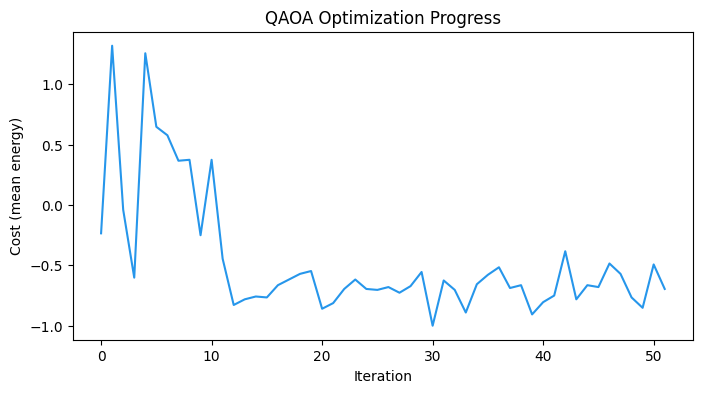

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(cost_history, color="#2696EB")
plt.xlabel("Iteration")
plt.ylabel("Cost (mean energy)")
plt.title("QAOA Optimization Progress")
plt.show()

## 結果をdecodeして解析する

最適化したparameterでsampleし、outcomeを解釈します。`BinaryModel.decode`はlogical
measurement順を元の変数IDへ戻し、すべての一意なassignmentをspin domainで評価
するため、binary変換は不要です。

In [13]:
optimized_gammas = tuple(float(value) for value in optimization.x[:layers])
optimized_betas = tuple(float(value) for value in optimization.x[layers:])
final_shots = 128 if docs_test_mode else 2048
final_record = qm.run(
    artifact,
    on=endpoint,
    parameters={"gammas": optimized_gammas, "betas": optimized_betas},
    shots=final_shots,
    seed=42,
)
decoded = model.decode(final_record.result)

cut_distribution = {}
best_qaoa_cut = 0
best_qaoa_assignment = None
for sample in decoded.samples:
    spins = dict(sample.assignment)
    cut = sum(spins[left] != spins[right] for left, right in EDGES)
    cut_distribution[cut] = cut_distribution.get(cut, 0) + sample.occurrences
    if cut > best_qaoa_cut:
        best_qaoa_cut = cut
        best_qaoa_assignment = spins

print(f"Best QAOA cut: {best_qaoa_cut} (optimal: {best_cut})")
print(f"Best partition: {best_qaoa_assignment}")

assert best_qaoa_assignment is not None
assert best_qaoa_cut <= best_cut
assert sum(cut_distribution.values()) == final_shots

Best QAOA cut: 5 (optimal: 5)
Best partition: {0: 1, 1: -1, 2: -1, 3: 1, 4: -1}


観測したcut valueの分布と、見つかった最良partitionを描画します。

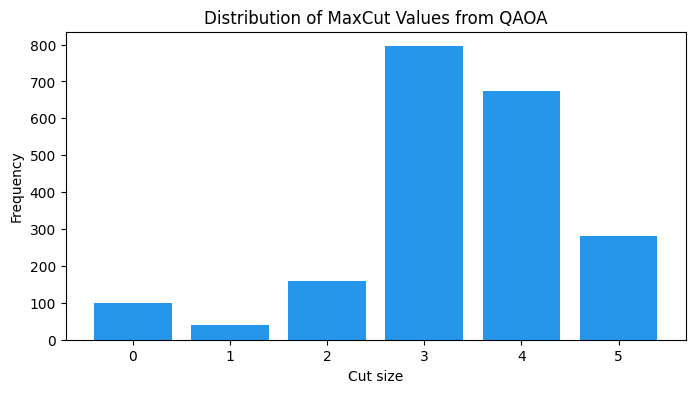

In [14]:
cuts = sorted(cut_distribution)
counts = [cut_distribution[cut] for cut in cuts]

plt.figure(figsize=(8, 4))
plt.bar([str(cut) for cut in cuts], counts, color="#2696EB")
plt.xlabel("Cut size")
plt.ylabel("Frequency")
plt.title("Distribution of MaxCut Values from QAOA")
plt.show()

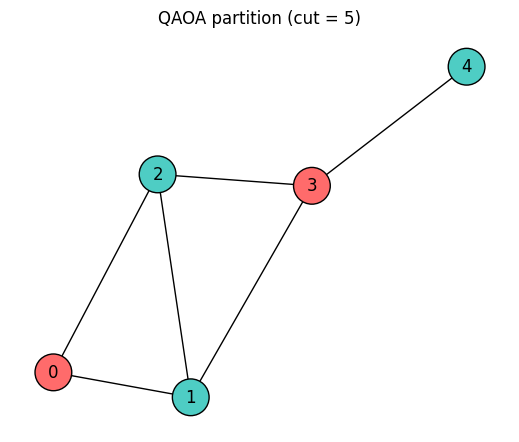

In [15]:
node_colors = [
    "#FF6B6B" if best_qaoa_assignment[node] == 1 else "#4ECDC4"
    for node in range(num_nodes)
]
plt.figure(figsize=(5, 4))
nx.draw(
    graph,
    positions,
    with_labels=True,
    node_color=node_colors,
    node_size=700,
    edgecolors="black",
)
plt.title(f"QAOA partition (cut = {best_qaoa_cut})")
plt.show()

source関数は、検査、resource estimation、コンパイル、反復シミュレーション、decodeの間で変わりません。`Reference`を対応するSDKまたはhardware endpointへ置き換えても、変わるのはtargetでの実現とtransportだけであり、型付きQAOA programや結果の意味は変わりません。

## まとめ

このtutorialでは次を行いました。

1. MaxCut問題を定義し、QUBOを経由せずspin変数上のIsing Hamiltonianとして
   直接記述しました。
2. `BinaryModel.from_ising`でspin-domain `BinaryModel`を構築しました。
3. superposition、cost layer、mixer layer、layered ansatz全体を構築しました。
4. 古典optimization loopを実行し、結果をdecodeして可視化しました。
5. `qamomile.stdlib.qaoa_state`が同じ合成を提供することを確認しました。

同じspin-firstの方法はweighted MaxCutやspin-glass問題にも適用できます。$h_i$と
$J_{ij}$の係数を`BinaryModel.from_ising`へ渡し、上のprogramを再利用します。